### **Unsupervised Learning**

In [1]:
import warnings
warnings.filterwarnings("ignore")

In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
from collections import Counter
import geopandas as gpd
from itertools import cycle, islice
from scipy.stats import norm
from ucimlrepo import fetch_ucirepo 
from shapely.geometry import Point
from sklearn.datasets import make_blobs, make_moons, make_circles, fetch_openml
from sklearn.cluster import KMeans, DBSCAN, OPTICS
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.metrics import silhouette_score, confusion_matrix, classification_report

### Clustering: KMeans

K-Means ალგორითმი ცდილობს მონაცემების დაჯგუფებას მათი მსგავსების მიხედვით. ის ცდილობს, მოძებნოს მონაცემებში რაიმე სახის კანონზომიერება.

K Means-ის შემთხვევაში, საჭიროა წინასწარ განვსაზღვროთ რამდენ ჯგუფად (კლასტერად) გვინდა მონაცემების დაყოფა. ალგორითმი თავდაპირველად შემთხვევითად ანაწილებს თითოეულ ჩანაწერს რომელიმე კლასტერში და გამოითვლის თითოეული კლასტერის ცენტრს (ცენტროიდს).

შემდეგ ის ასრულებს ორ ეტაპს განმეორებით:

1. მონაცემთა გადანაწილება: თითოეული მონაცემი ეკუთვნის იმ კლასტერს, რომლის ცენტრიც ყველაზე ახლოს არის.
2. ცენტროიდების ხელახლა გამოთვლა: თითოელი კლასტერისთვის გამოითვლება ახალი ცენტრი (ცენტროიდი).

ეს ორი ნაბიჯი მეორდება მანამ, სანამ მონაცემებსა და მათ შესაბამის ცენტრებს შორის ევკლიდურ დისტანციათა ჯამი აღარ იცვლება (აღარ მცირდება).

<img src="../../images/kmeans.png" width="800">

In [27]:
# Create Data
data = make_blobs(n_samples=200, n_features=2, 
                           centers=4, cluster_std=1.8, random_state=101)
df_points = pd.DataFrame(data[0], columns=["x", "y"])
df_points["labels"] = data[1]
df_points.head()

,x,y,labels
0,-6.428841,10.141117,3
1,5.868679,5.201104,2
2,-0.376109,3.264279,0
3,2.166792,9.563005,2
4,5.095086,7.207527,2


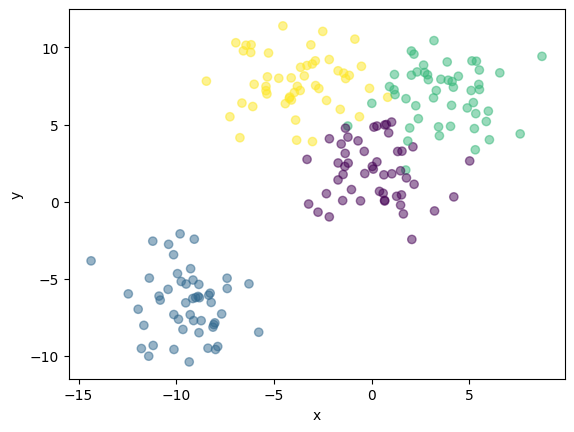

In [28]:
plt.scatter(df_points["x"], df_points["y"], c=df_points["labels"], alpha=0.5)
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [29]:
X = df_points[["x", "y"]]

In [30]:
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans.fit(X)

,n_clusters,4
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [31]:
kmeans.cluster_centers_

array([[-9.46941837, -6.56081545],
       [-0.0123077 ,  2.13407664],
       [-4.13591321,  7.95389851],
       [ 3.71749226,  7.01388735]])

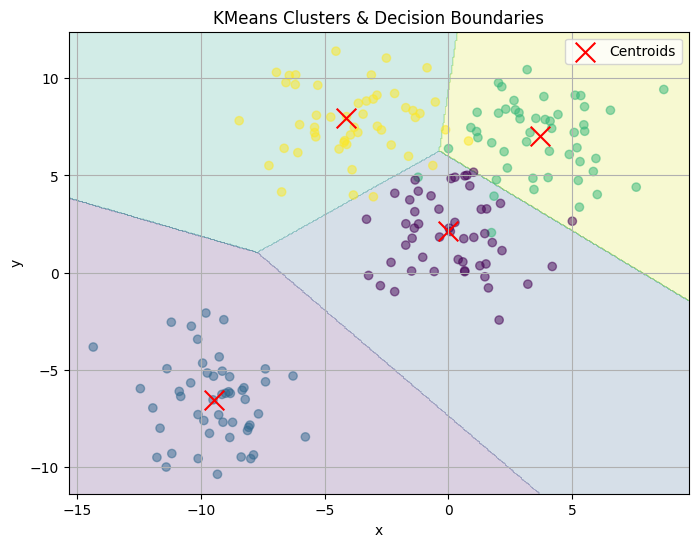

In [34]:
x_min, x_max = df_points["x"].min() - 1, df_points["x"].max() + 1
y_min, y_max = df_points["y"].min() - 1, df_points["y"].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500),
                     np.linspace(y_min, y_max, 500))

# თითოეული წერტილისთვის პროგნოზი (Predict cluster for each grid point)
Z = kmeans.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.2, cmap="viridis")  # Decision boundary
plt.scatter(df_points["x"], df_points["y"], c=df_points["labels"], alpha=0.5)
plt.scatter(kmeans.cluster_centers_[:, 0],  
            kmeans.cluster_centers_[:, 1], 
            c="red", marker="x", s=200, label="Centroids") # კლასტერების ცენტრები
plt.legend()
plt.title("KMeans Clusters & Decision Boundaries")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.show()

In [35]:
kmeans.labels_

array([2, 3, 1, 3, 3, 0, 3, 1, 3, 1, 2, 1, 3, 3, 2, 1, 3, 1, 0, 2, 0, 1,
       1, 0, 2, 0, 0, 1, 3, 3, 2, 0, 3, 1, 1, 2, 0, 0, 0, 1, 0, 2, 2, 2,
       1, 3, 2, 1, 0, 1, 1, 2, 3, 1, 0, 2, 1, 1, 2, 3, 0, 3, 0, 2, 3, 1,
       0, 3, 3, 0, 3, 1, 0, 1, 0, 3, 3, 1, 2, 1, 1, 0, 3, 0, 1, 1, 1, 2,
       1, 0, 0, 0, 0, 1, 1, 0, 3, 2, 0, 3, 1, 0, 1, 1, 3, 1, 0, 3, 0, 0,
       3, 2, 2, 3, 0, 3, 2, 2, 3, 2, 1, 2, 1, 2, 1, 3, 2, 1, 0, 2, 2, 2,
       1, 0, 0, 2, 3, 2, 3, 1, 0, 3, 0, 2, 2, 3, 1, 0, 2, 2, 2, 2, 1, 3,
       1, 2, 3, 3, 3, 1, 3, 1, 1, 2, 0, 2, 1, 3, 2, 1, 3, 1, 2, 3, 1, 2,
       3, 3, 0, 3, 2, 0, 0, 2, 0, 0, 0, 0, 0, 1, 0, 3, 3, 2, 0, 1, 3, 3,
       0, 1], dtype=int32)

In [47]:
# actual
df_points["labels"].value_counts()

labels
3    50
2    50
0    50
1    50
Name: count, dtype: int64

In [46]:
# from model
pd.Series(kmeans.labels_).map({3:2, 2:3, 1:0, 0:1}).value_counts()

0    54
2    50
1    50
3    46
Name: count, dtype: int64

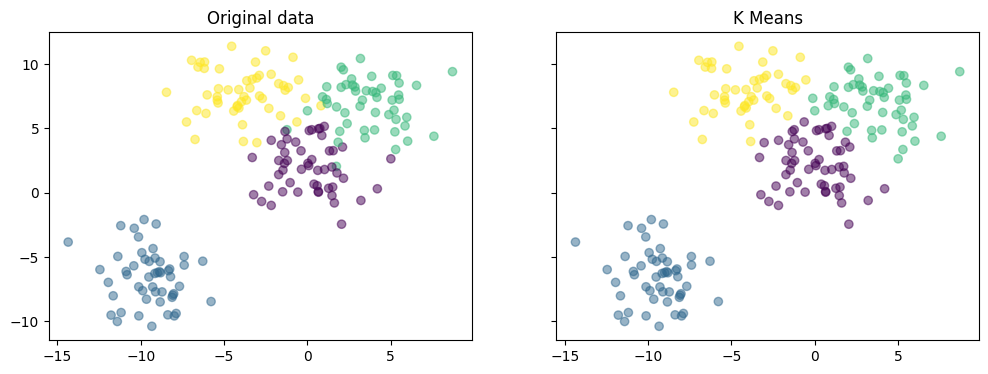

In [45]:
fig, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize=(12,4))
ax1.set_title("Original data")
ax1.scatter(df_points["x"], df_points["y"], c=df_points["labels"], alpha=0.5)
ax2.set_title("K Means")
ax2.scatter(df_points["x"], df_points["y"], c=pd.Series(kmeans.labels_).map({3:2, 2:3, 1:0, 0:1}), alpha=0.5);

ამ მაგალითისთვის მარტივი იყო n_clusters პარამეტრის არჩევა, რადგანაც თავიდანვე მონაცემები ისე იყო შედგენილი. უცხო მონაცემებისთვის არც თუ ისე მარტივია ამ პარამეტრის არჩევა. კლასტერების რაოდენობის არასწორმა არჩევამ შეიძლება განაპირობოს არასწორი ჯგუფების გამოყოფა.
მაგალითად:
<img src="../../images/kmeans_k.png" width="1000">

* Inertia - წერტილებიდან უახლოეს კლასტერის ცენტრამდე მანძილების კვადრატების ჯამი.
დაბალი Inertia → უფრო მჭიდრო კლასტერები

* Silhouette Score - ზომავს, რამდენად კარგად ეკუთვნის წერტილი საკუთარ კლასტერს სხვა კლასტერთან შედარებით.
დიაპაზონი: –1-დან +1-მდე:
    - +1 → კლასტერები კარგადაა გამოყოფილი
    - 0 → კლასტერები ერთმანეთს ეხება
    - < 0 → წერტილი შესაძლოა არასწორ კლასტერში იყოს

| მეტრიკა          | რას ზომავს            | საუკეთესო მნიშვნელობა | რისთვის გამოიყენება     |
| ---------------- | --------------------- | --------------------- | ----------------------- |
| Inertia          | რამდენად კომპაქტურია კლასტერები          | დაბალი                | Elbow მეთოდი            |
| Silhouette Score | კლასტერის შიდა სიმჭიდროვე და კლასტერთაშორისი დაშორება | მაღალი                | საუკეთესო k-ს არჩევა |

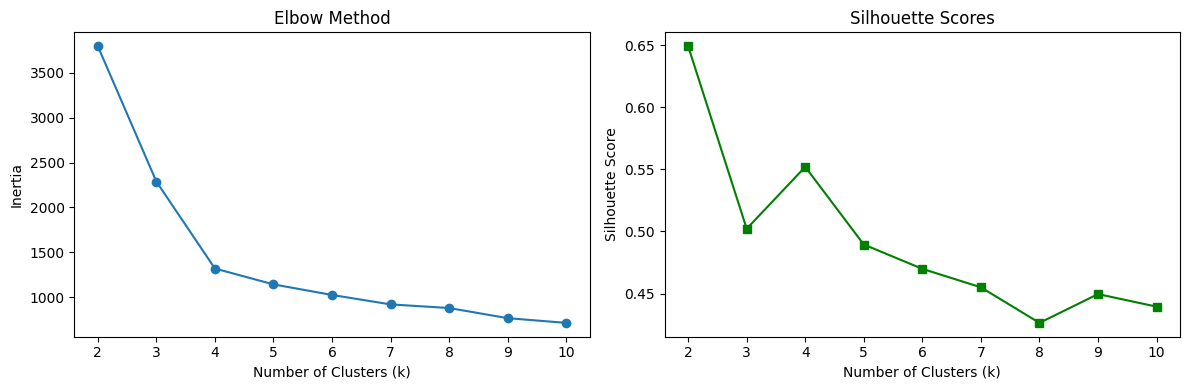

In [12]:
inertias = []
silhouette_scores = []
K_range = range(2, 11) 

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(data[0])
    
    inertia = kmeans.inertia_
    score = silhouette_score(data[0], kmeans.labels_)
    
    inertias.append(inertia)
    silhouette_scores.append(score)


plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(K_range, inertias, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.subplot(1, 2, 2)
plt.plot(K_range, silhouette_scores, marker="s", color="green")
plt.title("Silhouette Scores")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.tight_layout()
plt.show()

### College Data

777 observations, 18 variables:
* Private - A factor with levels No and Yes indicating private or public university
* Apps - Number of applications received
* Accept - Number of applications accepted
* Enroll - Number of new students enrolled
* Top10perc - Pct. new students from top 10% of H.S. class
* Top25perc - Pct. new students from top 25% of H.S. class
* F.Undergrad - Number of fulltime undergraduates
* P.Undergrad - Number of parttime undergraduates
* Outstate - Out-of-state tuition
* Room.Board - Room and board costs
* Books - Estimated book costs
* Personal - Estimated personal spending
* PhD - Pct. of faculty with Ph.D.’s
* Terminal - Pct. of faculty with terminal degree
* S.F.Ratio - Student/faculty ratio
* perc.alumni - Pct. alumni who donate
* Expend - Instructional expenditure per student
* Grad.Rate - Graduation rate

In [48]:
# მონაცემების ჩატვირთვა
df_college = pd.read_csv("../../datasets/uni_data/college_data.csv", index_col=0)
df_college.head()

,Private,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
Abilene Christian University,Yes,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60
Adelphi University,Yes,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56
Adrian College,Yes,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54
Agnes Scott College,Yes,417,349,137,60,89,510,63,12960,5450,450,875,92,97,7.7,37,19016,59
Alaska Pacific University,Yes,193,146,55,16,44,249,869,7560,4120,800,1500,76,72,11.9,2,10922,15


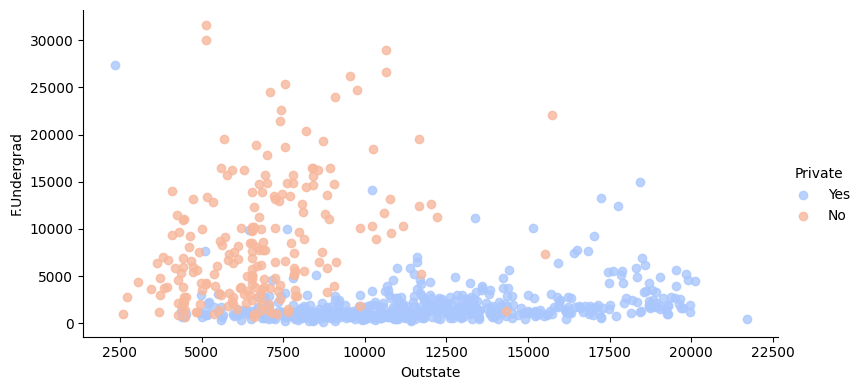

In [49]:
sns.lmplot(
    x="Outstate",
    y="F.Undergrad",
    data=df_college,
    hue="Private",
    palette="coolwarm",
    height=4,  
    aspect=2,
    fit_reg=False
);

In [50]:
X = df_college[["Outstate", "F.Undergrad"]].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [51]:
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans.fit(X_scaled)

,n_clusters,2
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [52]:
df_college["Private"] = df_college["Private"].map({"No": 0, "Yes": 1})

In [53]:
print(classification_report(df_college["Private"], kmeans.labels_))

              precision    recall  f1-score   support

           0       0.79      0.95      0.86       212
           1       0.98      0.91      0.94       565

    accuracy                           0.92       777
   macro avg       0.89      0.93      0.90       777
weighted avg       0.93      0.92      0.92       777



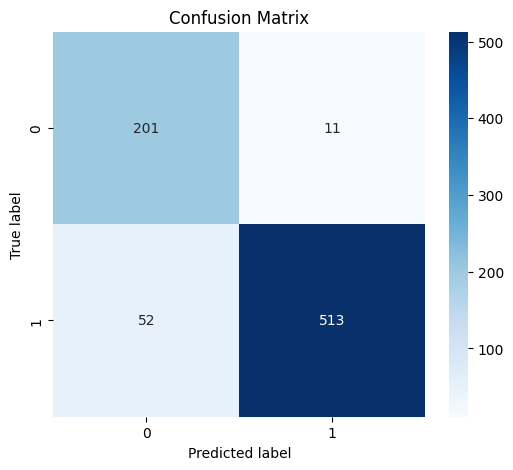

In [54]:
# confusion matrix
conf_matrix = confusion_matrix(df_college["Private"], kmeans.labels_)

plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.show()

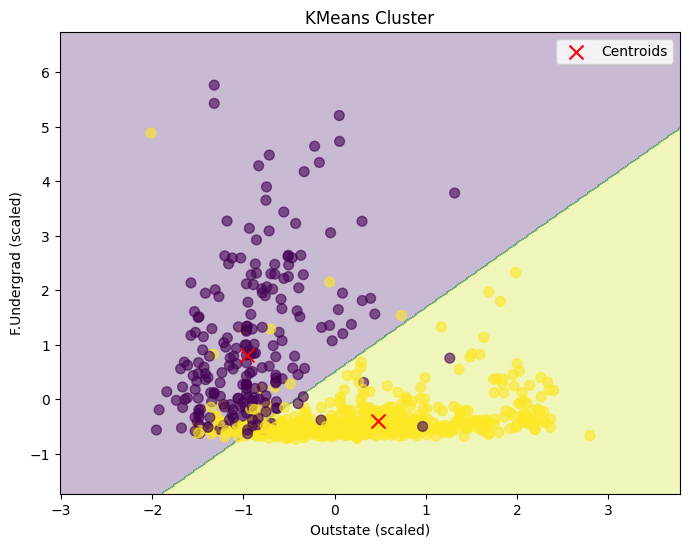

In [55]:
x_min, x_max = X_scaled[:, 0].min() - 1, X_scaled[:, 0].max() + 1
y_min, y_max = X_scaled[:, 1].min() - 1, X_scaled[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

Z = kmeans.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, cmap="viridis", alpha=0.3)  # decision boundaries
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=df_college["Private"], cmap="viridis", s=50, alpha=0.6)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            c="red", s=100, marker="x", label="Centroids")
plt.title("KMeans Cluster")
plt.xlabel("Outstate (scaled)")
plt.ylabel("F.Undergrad (scaled)")
plt.legend()
plt.show()

#### MNIST: ხელნაწერი ციფრები (0-9). (data - 28x28 პიქსელების grayscale სურათები)

In [60]:
# Load data
df_mnist, labels = fetch_openml("mnist_784", version=1, return_X_y=True)
df_mnist.head()

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


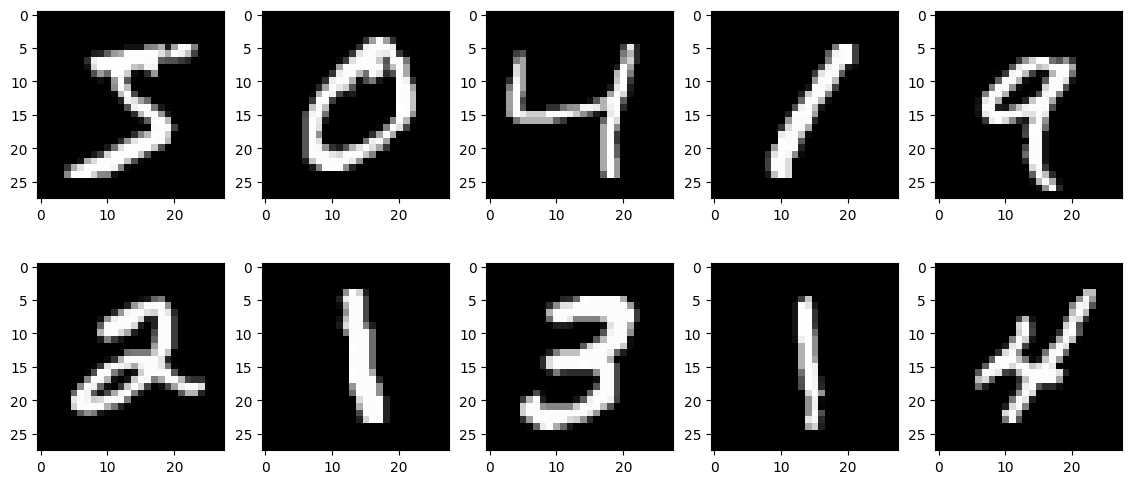

In [61]:
# დავბეჭდოთ პირველი 10 სურათი. პიქსელის მნიშვნელობების დიაპაზონი 0≤P≤255, 0 (შავი), 255 (თეთრი), შუა მნიშვნელობები (1-254) → ნაცრისფერი ელფერები
# Each row has a shape (784,) and presents 28x28 pixel grayscale images
fig=plt.figure(figsize=(14, 6))
for i in range(0,10):
    fig.add_subplot(2,5,i+1)
    plt.imshow(df_mnist.values[i].reshape(28,28), cmap="gray")
plt.show()

In [67]:
# k-means-Clustering with k=10 
km = KMeans(n_clusters=10, max_iter=100, n_init=1, random_state=1, tol=0)
km.fit(df_mnist)

KMeans(max_iter=100, n_clusters=10, n_init=1, random_state=1, tol=0)

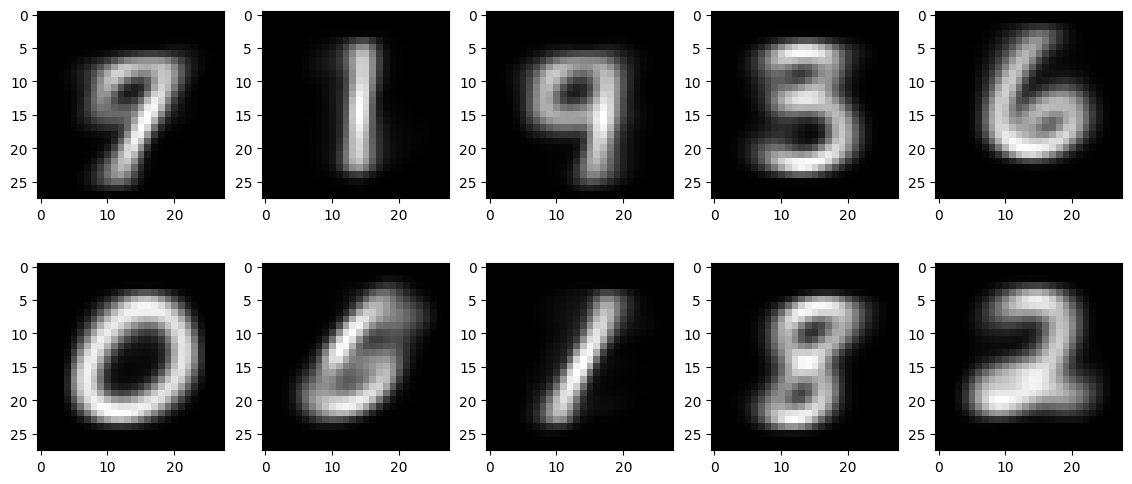

In [70]:
# Cluster mean values visualized:
fig=plt.figure(figsize=(14, 6))
for i in range(0,10):
  fig.add_subplot(2,5,i+1)
  plt.imshow(km.cluster_centers_[i,:].reshape(28,28), cmap="gray")
plt.show()

In [71]:
# Most frequent labels per cluster:
for i in range(10):
  print("Cluster", i, Counter(labels[km.labels_==i]))

Cluster 0 Counter({'7': 4403, '9': 2852, '4': 2191, '5': 215, '8': 185, '2': 78, '3': 46, '1': 10, '0': 7, '6': 4})
Cluster 1 Counter({'1': 4293, '3': 460, '2': 431, '7': 377, '8': 334, '9': 267, '6': 207, '4': 182, '5': 166, '0': 3})
Cluster 2 Counter({'4': 3733, '9': 3457, '7': 2085, '5': 427, '2': 215, '8': 208, '3': 185, '6': 66, '0': 43, '1': 6})
Cluster 3 Counter({'3': 4605, '5': 2127, '8': 1177, '2': 318, '0': 290, '9': 86, '6': 39, '1': 8, '7': 5})
Cluster 4 Counter({'6': 4443, '0': 173, '4': 170, '2': 151, '5': 70, '8': 54, '3': 33, '9': 16, '1': 7, '7': 4})
Cluster 5 Counter({'0': 5040, '6': 74, '5': 59, '2': 56, '9': 50, '8': 37, '3': 21, '7': 21, '4': 9})
Cluster 6 Counter({'6': 1925, '5': 1845, '0': 1260, '3': 508, '8': 339, '4': 255, '2': 239, '9': 31, '7': 12, '1': 7})
Cluster 7 Counter({'1': 3527, '2': 433, '8': 319, '7': 313, '5': 268, '4': 235, '9': 93, '3': 53, '6': 45, '0': 4})
Cluster 8 Counter({'8': 4120, '5': 1129, '3': 1024, '2': 205, '9': 87, '0': 74, '7': 20, 

### DBSCAN (Density-Based Spatial Clustering of Applications with Noise)

DBSCAN ქმნის კლასტერებს მჭიდროდ მყოფი მყოფი მონაცემებისათვის და გამოყოფს მარტოხელა მონაცემებს როგორც ანომალიებს. DBSCAN არ საჭიროებს კლასტერების რაოდენობის წინასწარ განსაზღვრას. 

| ტერმინი             | აღწერა                                                                                     |
| ------------------- | ------------------------------------------------------------------------------------------ |
| ε (epsilon)   | მაქსიმალური მანძილი, რომლის ფარგლებშიც ვეძებთ მეზობელ მონაცემებს                           |
| min_samples   | მინიმალური რაოდენობა მონაცემებისა, რომლებიც საჭიროა ბირთვული (core) მონაცემის სტატუსისთვის |
| Core Point     | მონაცემი, რომელსაც თავისი ε-მეზობლობაში აქვს მინიმუმ `min_samples` მონაცემი                |
| Border Point    | მონაცემი, რომელიც თვითონ არ არის core, მაგრამ იმყოფება core მონაცემის მეზობლობაში          |
| Noise / Outlier | მონაცემი, რომელიც არ არის core და არ არის core-ის მეზობლობაში — ანუ გამონაკლისი            |

---

1. აირჩიე მონაცემი, რომელიც ჯერ არ არის მონახულებული.
2. მოძებნე მისი ε-მეზობლები.
3. თუ მეზობლების რაოდენობა ≥ `min_samples`, მოინიშნე როგორც core მონაცემი და შექმენი კლასტერი.
4. დაამატე მეზობლები ამავე კლასტერის შემადგენლობაში. თუ მეზობლებსაც აქვთ საკმარისი მეზობლები, პროცესი განმეორდება რეკურსიულად.
5. თუ მონაცემი არ აკმაყოფილებს ბირთვის პირობებს და არ არის მეზობელი ბირთვთან (არც core და არც border მონაცემია) — გამოაცხადე როგორც ანომალია - noise.
6. გააგრძელე სანამ ყველა მონაცემი არ იქნება მონახულებული.
   
<img src="../../images/dbscan.png" width="800">

In [56]:
# Create data
X, y = make_moons(n_samples=1000, noise=0.05, random_state=42)

In [57]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [58]:
dbscan = DBSCAN(eps=0.2, min_samples=5)
labels = dbscan.fit_predict(X_scaled)

In [59]:
pd.Series(dbscan.labels_).value_counts()

0    500
1    500
Name: count, dtype: int64

In [60]:
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)  # Exclude noise label (-1)
n_noise = list(labels).count(-1)  # Count how many points are labeled as noise

print(f"Number of clusters: {n_clusters}")
print(f"Number of noise points: {n_noise}")

Number of clusters: 2
Number of noise points: 0


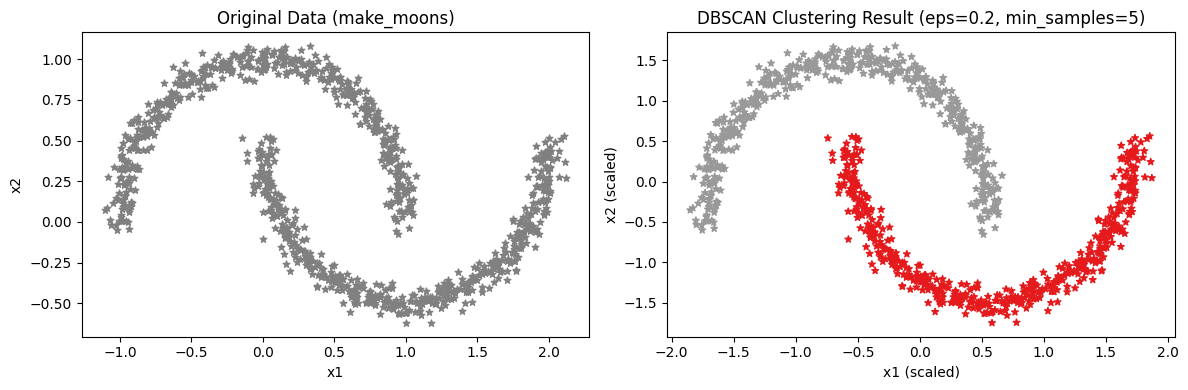

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(X[:, 0], X[:, 1], c="grey", s=25, marker="*", cmap="Set1")
axes[0].set_title("Original Data (make_moons)")
axes[0].set_xlabel("x1")
axes[0].set_ylabel("x2")
axes[0].grid(False)
axes[1].scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels, s=25, marker="*", cmap="Set1")
axes[1].set_title(f"DBSCAN Clustering Result (eps=0.2, min_samples=5)")
axes[1].set_xlabel("x1 (scaled)")
axes[1].set_ylabel("x2 (scaled)")
axes[1].grid(False)
plt.tight_layout()
plt.show()

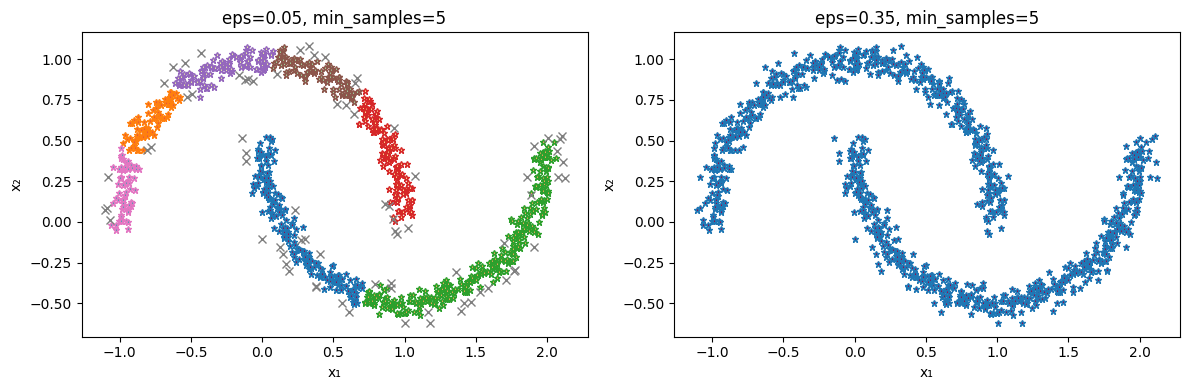

In [62]:
# მნიშვნელოვანია eps, min_samples პარამეტრების სწორად შერჩევა
db_1 = DBSCAN(eps=0.05, min_samples=5).fit(X)
db_2 = DBSCAN(eps=0.35, min_samples=5).fit(X)

labels_1 = db_1.labels_
labels_2 = db_2.labels_

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, labels, eps in zip(axes, [labels_1, labels_2], [0.05, 0.35]):
    unique_labels = set(labels)
    colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels)))
    for k, col in zip(unique_labels, colors):
        class_member_mask = (labels == k)
        xy = X[class_member_mask]
        if k == -1:
            ax.plot(xy[:, 0], xy[:, 1], "x", markerfacecolor="r", label="Noise")
        else:
            ax.plot(xy[:, 0], xy[:, 1], "*", markerfacecolor=col, markersize=5)
    ax.set_title(f"eps={eps}, min_samples=5")
    ax.set_xlabel("x₁")
    ax.set_ylabel("x₂")

plt.tight_layout()
plt.show()

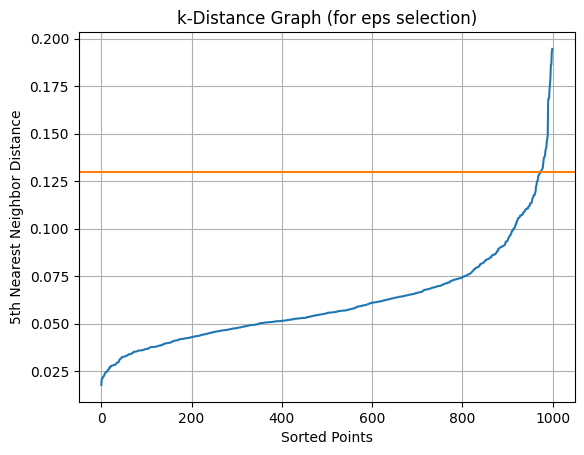

In [63]:
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)
distances = np.sort(distances[:, -1])

plt.plot(distances)
plt.title("k-Distance Graph (for eps selection)")
plt.axhline(0.13, color="C1")
plt.ylabel("5th Nearest Neighbor Distance")
plt.xlabel("Sorted Points")
plt.grid()
plt.show()

#### DBSCAN-ს არ აქვს predict() მეთოდი, მხოლოდ fit_predict() მეთთოდია ამ კლასისთვის განსაზღვრული. ანუ როდესაც ახალი მონაცემი მოვა, DBSCAN-ს არ შეუძლია განსაზღვროს რომელ კლასტერს ეკუთვნის. KNeighborsClassifier-ის დახმარებით:

In [66]:
dbscan = DBSCAN(eps=0.2, min_samples=5)
labels = dbscan.fit_predict(X_scaled)

In [67]:
knn = KNeighborsClassifier(n_neighbors=5)
core_samples = dbscan.components_
core_labels = dbscan.labels_[dbscan.core_sample_indices_]
knn.fit(core_samples, core_labels)

X_new = np.array([[-0.5, 0], [0, 0.5], [1, -0.1], [2, 1]])
knn.predict(X_new)

array([0, 1, 1, 0])

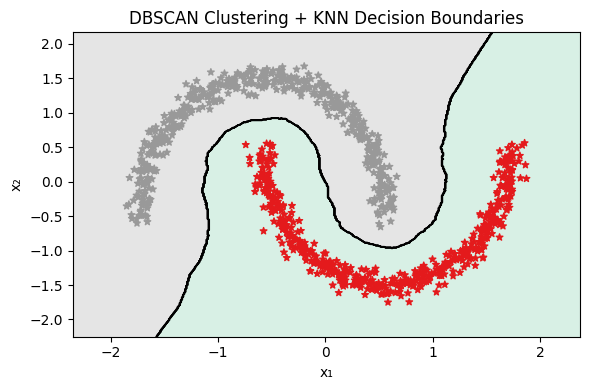

In [68]:
h = 0.01
x_min, x_max = X_scaled[:, 0].min() - 0.5, X_scaled[:, 0].max() + 0.5
y_min, y_max = X_scaled[:, 1].min() - 0.5, X_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))
grid = np.c_[xx.ravel(), yy.ravel()]
Z = knn.predict(grid).reshape(xx.shape)

plt.figure(figsize=(6, 4))
plt.contourf(xx, yy, Z, cmap="Pastel2", alpha=0.5)  
plt.contour(xx, yy, Z, colors="k", linewidths=1) 
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels, s=25, marker="*", cmap="Set1") 
plt.xlabel("x₁")
plt.ylabel("x₂")
plt.title("DBSCAN Clustering + KNN Decision Boundaries")
plt.tight_layout()
plt.show()

### NYC taxi dataset

In [75]:
# მონაცემების ჩატვირთვა
df_taxi = pd.read_csv("../../datasets/nyc_taxi/yellow_tripdata_manhattan.csv")
df_taxi.head()

,pickup_longitude,pickup_latitude
0,-73.980103,40.762669
1,-74.002464,40.751205
2,-73.982315,40.740154
3,-73.979851,40.765785
4,-74.006348,40.733231


In [84]:
# ლონგიტუდისა და ლატიტუდის კოორდინატთა სისტემაში გადაყვანა
df_taxi["geometry"] = [Point(xy) for xy in zip(df_taxi["pickup_longitude"], df_taxi["pickup_latitude"])]
df_taxi.head()

,pickup_longitude,pickup_latitude,geometry
0,-73.980103,40.762669,POINT (-73.9801025390625 40.76266860961914)
1,-74.002464,40.751205,POINT (-74.0024642944336 40.75120544433594)
2,-73.982315,40.740154,POINT (-73.98231506347656 40.74015426635742)
3,-73.979851,40.765785,POINT (-73.97985076904298 40.76578521728515)
4,-74.006348,40.733231,POINT (-74.00634765625 40.73323059082031)


In [85]:
type(df_taxi)

pandas.core.frame.DataFrame

In [86]:
# Geopanda DataFrame
df_geo = gpd.GeoDataFrame(df_taxi, geometry="geometry", crs="EPSG:4326")  # crs (Coordinate Reference System), პარამეტრი EPSG:4326 ნიშნავს WGS 84 (World Geodetic System 1984)
df_geo = df_geo.to_crs(epsg=3857) # Web Mercator - გადაგვყავს მეტრებში
df_geo.head()

,pickup_longitude,pickup_latitude,geometry
0,-73.980103,40.762669,POINT (-8235427.343 4977398.112)
1,-74.002464,40.751205,POINT (-8237916.643 4975713.495)
2,-73.982315,40.740154,POINT (-8235673.641 4974089.698)
3,-73.979851,40.765785,POINT (-8235399.317 4977856.177)
4,-74.006348,40.733231,POINT (-8238348.937 4973072.511)


In [87]:
type(df_geo)

geopandas.geodataframe.GeoDataFrame

In [74]:
coords = np.column_stack([df_geo.geometry.x, df_geo.geometry.y])
dbscan = DBSCAN(eps=100, min_samples=10).fit(coords)  # eps in Meter (~100m)

In [75]:
df_geo["cluster"] = dbscan.labels_
df_geo = df_geo[df_geo["cluster"] != -1]
df_geo.head()

,pickup_longitude,pickup_latitude,geometry,cluster
0,-73.980103,40.762669,POINT (-8235427.343 4977398.112),1
1,-74.002464,40.751205,POINT (-8237916.643 4975713.495),95
2,-73.982315,40.740154,POINT (-8235673.641 4974089.698),0
3,-73.979851,40.765785,POINT (-8235399.317 4977856.177),1
4,-74.006348,40.733231,POINT (-8238348.937 4973072.511),2


In [76]:
# Convert to WGS84 for Plotly (lon/lat in degrees)
df_plotly = df_geo.to_crs(epsg=4326).copy()
df_plotly["lon"] = df_plotly.geometry.x
df_plotly["lat"] = df_plotly.geometry.y
df_plotly["cluster"] = df_plotly["cluster"].astype(str)

fig = px.scatter_mapbox(
    df_plotly,
    lat="lat",
    lon="lon",
    color="cluster",
    zoom=11,
    opacity=0.5,
    mapbox_style="carto-positron",
    height=600,
    title="DBSCAN Clustering of NYC Taxi Pickups (Manhattan)"
)
fig.update_layout(legend_title_text="Cluster ID")
fig.show()

### OPTICS (Ordering Points To Identify the Clustering Structure) 

OPTICS DBSCAN-ის მსგავსი ალგორითმია, მაგრამ აქვს ერთი მნიშვნელოვანი უპირატესობა: არ არის მგრძნობიარე eps მნიშვნელობის შერჩევაზე, რაც ხშირად პრობლემურია DBSCAN-ში.

<img src="../../images/density.png" width="600">

OPTICS ქმნის ქულების დალაგებულ სიას და განსაზღვრავს reachability distance, რაც უკეთ აჩვენებს მონაცემთა შიდა სტრუქტურას.

| პარამეტრი              | ახსნა                                                                                                                                                                                                                                                  |
| ---------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| **`min_samples`**      | მინიმალური რაოდენობა მეზობლების, რომელიც საჭიროა იმისთვის, რომ წერტილი ჩაითვალოს **ბირთვულ წერტილად** (*core point*). როგორც DBSCAN-ში. მაგალითად, თუ `min_samples=10`, წერტილი ბირთვულია, თუ მას ჰყავს მინიმუმ 10 მეზობელი.       |
| **`xi`**               | აკონტროლებს reachability distance, ანუ რამდენად მკვეთრად უნდა შეიცვალოს სიმკვრივე, რომ ჩაითვალოს ახალი კლასტერად. მაგალითად: `xi=0.05` ნიშნავს 5%-იან ცვლილებას reachability-ში. რაც უფრო მცირეა `xi`.|
| **`min_cluster_size`** | განსაზღვრავს კლასტერის მინიმალურ ზომას – შეიძლება იყოს მთელი რიცხვი (მაგ. 20 წერტილი) ან პროცენტული მნიშვნელობა (მაგ. `0.05` ნიშნავს 5% მთლიანი მონაცემებიდან).          |


In [88]:
X, y = make_blobs(n_samples=1000, centers=3, cluster_std=[0.5, 1, 2.5], random_state=42)

In [89]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [90]:
dbscan = DBSCAN(eps=1, min_samples=10)
labels_db = dbscan.fit_predict(X_scaled)

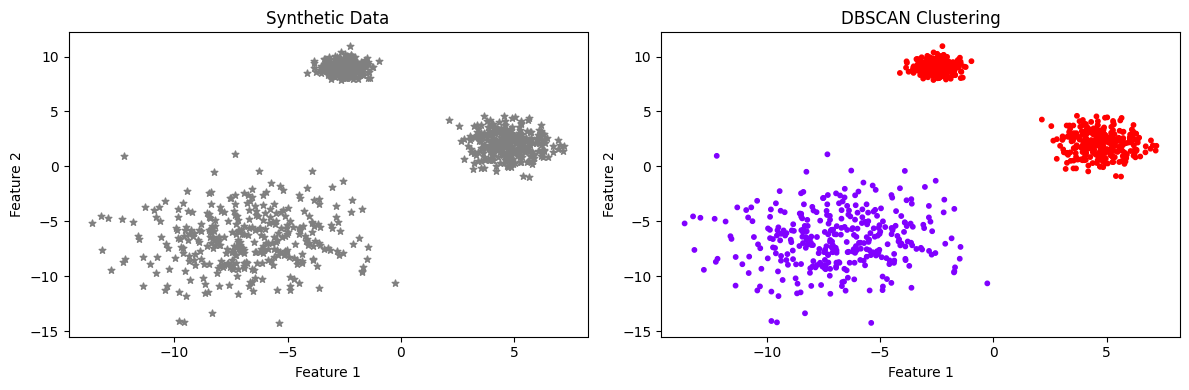

In [91]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(X[:, 0], X[:, 1], c="grey", s=25, marker="*")
axes[0].set_title("Synthetic Data")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")

axes[1].scatter(X[:, 0], X[:, 1], c=labels_db, cmap="rainbow", s=10)
axes[1].set_title("DBSCAN Clustering")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

In [98]:
optics = OPTICS(min_samples=10, xi=0.1, min_cluster_size=0.05)
labels_optics = optics.fit_predict(X_scaled)

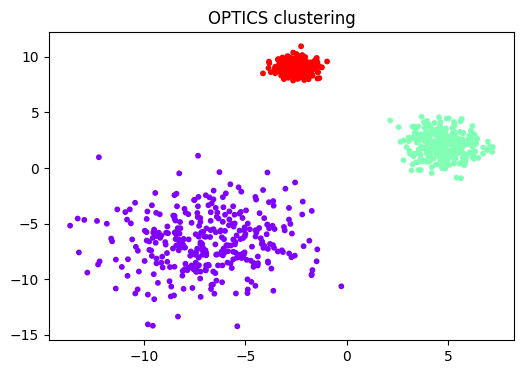

In [99]:
plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], c=labels_optics, cmap="rainbow", s=10)
plt.title("OPTICS clustering")
plt.show()

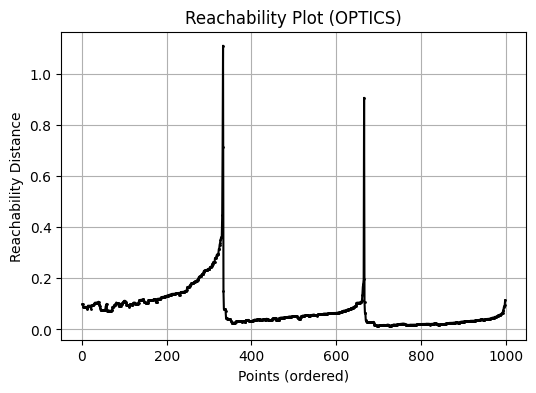

In [100]:
space = np.arange(len(X))
reachability = optics.reachability_[optics.ordering_]
labels = optics.labels_[optics.ordering_]

plt.figure(figsize=(6, 4))
plt.plot(space, reachability, marker=".", color="black", markersize=2)
plt.title("Reachability Plot (OPTICS)")
plt.xlabel("Points (ordered)")
plt.ylabel("Reachability Distance")
plt.grid()
plt.show()

| xi            | როდის გამოვიყენო                                |
| ------------- | ----------------------------------------------- |
| `0.01`        | თუ გრაფში ცვლილებები ძალიან რბილია              |
| `0.05`        | სტანდარტული ვარიანტი, კარგია უმეტეს შემთხვევაში |
| `0.1` ან მეტი | როცა კლასტერს შორის მკვეთრი ზღვარია             |

OPTICS უკეთესია როცა:

* კლასტერები არ არიან სფერული
* eps შერჩევა რთულია
* გსურთ სრული სტრუქტურის ნახვა Reachability Plot-ით

DBSCAN უკეთესია როცა:

* eps შეგიძლიათ ზუსტად შეარჩიოთ
* გსურთ სწრაფი კლასტერიზაცია
  
| მახასიათებელი        | DBSCAN                            | OPTICS                                          |
| -------------------- | --------------------------------- | ----------------------------------------------- |
| ცვალებადი სიმკვრივე   | ცუდად მუშაობს                     | კარგად მუშაობს                    |
| გამოყოფის სიზუსტე    | ზოგჯერ ვერ არჩევს რთულ კლასტერებს | უკეთ ახერხებს კომპლექსური სტრუქტურის გამოვლენას |
| სიჩქარე              | სწრაფია                           | ნელა მუშაობს, მაგრამ შედეგი უფრო მდგრადია      |
| ვიზუალიზაცია         | მარტივი                           | დამატებით გთავაზობთ Reachability Plot-ს         |

### Mice Protein Expression dataset
მონაცემთა ნაკრები შეიცავს 77 თაგვის სხვადასხვა ცილების დონეებს. თითოეული თაგვი წარმოდგენილია 77 ცილოვანი მახასიათებლით.
    
| მახასიათებელი        | მნიშვნელობა                                                                               |
| -------------------- | ----------------------------------------------------------------------------------------- |
| `Genotype`           | გენოტიპი (Control / Ts65Dn)                                                               |
| `Treatment`          | მკურნალობა (Saline / Memantine)                                                           |
| `Behavior`           | ქცევითი მდგომარეობა (C/S)                                                                 |
| `DYRK1A`, `pS6`, ... | ცილების ექსპრესიის დონეები                           |
| `class`              | Target Label  |

In [109]:
# მონაცემების ჩატვირთვა
mice_protein_expression = fetch_ucirepo(id=342) 
X = mice_protein_expression.data.features 
y = mice_protein_expression.data.targets 
X = X.iloc[:, :77].dropna()
X.head()

,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,pELK_N,...,SHH_N,BAD_N,BCL2_N,pS6_N,pCFOS_N,SYP_N,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N
75,0.649781,0.828696,0.405862,2.921435,5.167979,0.207174,0.176640,3.728084,0.239283,1.666579,...,0.239752,0.139052,0.112926,0.132001,0.129363,0.486912,0.125152,0.146865,0.143517,1.627181
76,0.616481,0.841974,0.388584,2.862575,5.194163,0.223433,0.167725,3.648240,0.221030,1.565150,...,0.249031,0.133787,0.121607,0.139008,0.143084,0.467833,0.112857,0.161132,0.145719,1.562096
77,0.637424,0.852882,0.400561,2.968155,5.350820,0.208790,0.173261,3.814545,0.222300,1.741732,...,0.247956,0.142324,0.130261,0.134804,0.147673,0.462501,0.116433,0.160594,0.142879,1.571868
78,0.576815,0.755390,0.348346,2.624901,4.727509,0.205892,0.161192,3.778530,0.194153,1.505475,...,0.233225,0.133637,0.107321,0.118982,0.121290,0.479110,0.102831,0.144238,0.141681,1.646608
79,0.542545,0.757917,0.350051,2.634509,4.735602,0.210526,0.165671,3.871971,0.194297,1.531613,...,0.244469,0.133358,0.112851,0.128635,0.142617,0.438354,0.110614,0.155667,0.146408,1.607631


In [113]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [128]:
optics = OPTICS(min_samples=5, xi=0.03, min_cluster_size=0.03)
optics.fit(X_scaled)

OPTICS(min_cluster_size=0.03, xi=0.03)

In [129]:
df_mice = X.copy()
df_mice["class"] = y.iloc[X.index]
df_mice["cluster"] = optics.labels_
df_mice.groupby(["class", "cluster"]).size().unstack(fill_value=0)

cluster,-1,0,1,2,3,4,5,6,7
class,,,,,,,,,
c-CS-m,38,7,0,0,0,0,0,0,0
c-CS-s,52,0,23,0,0,0,0,0,0
c-SC-m,18,0,0,0,0,0,0,27,15
c-SC-s,59,0,0,0,0,0,16,0,0
t-CS-m,66,9,0,0,0,15,0,0,0
t-CS-s,35,0,0,27,0,13,0,0,0
t-SC-m,45,0,0,0,0,0,0,0,15
t-SC-s,42,0,0,0,30,0,0,0,0


### Gaussian Mixture Model (GMM)

Gaussian Mixture Model მიიჩნევს, რომ მონაცემთა პოპულაცია შედგება რამდენიმე გაუსის (ნორმალური) განაწილებისაგან.
ყოველ კლასტერს აქვს თავისი mean და covariance.

---
GMM იყენებს EM (Expectation-Maximization) ალგორითმს:

1. ინიციალიზაცია: დავიწყოთ საშუალოებისა და კოვარიაციების შემთხვევითი ვარაუდით.
2. მოლოდინი: ვთვლით, რა ალბათობით ეკუთვნის თითოეული წერტილი თითოეულ გაუსიანურ კომპონენტს.
3. მაქსიმიზაცია: განვაახლებთ საშუალოებს, კოვარიანციებს და წონებს მიღებული ალბათობების საფუძველზე.
4. ვიმეორებთ ამ ნაბიჯებს, სანამ მოდელი არ დაასტაბილურდება.

GMM-ის ძირითადი ფორმულა:

$$
P(x) = \sum_{i=1}^{K} w_i \cdot \mathcal{N}(x \mid \mu_i, \Sigma_i),
$$
სადაც

* $K$ — კომპონენტების რაოდენობა (კლასტერები)
* $w_i$ — i კომპონენტის წონა (უნდა აკმაყოფილებდეს: $\sum w_i = 1$)
* $\mu_i$ — საშუალო (mean)
* $\Sigma_i$ — კოვარიანციის მატრიცა (ან დისპერსია ერთგანზომილებაში)
* $\mathcal{N}(x \mid \mu_i, \Sigma_i)$ — გაუსიანური განაწილება

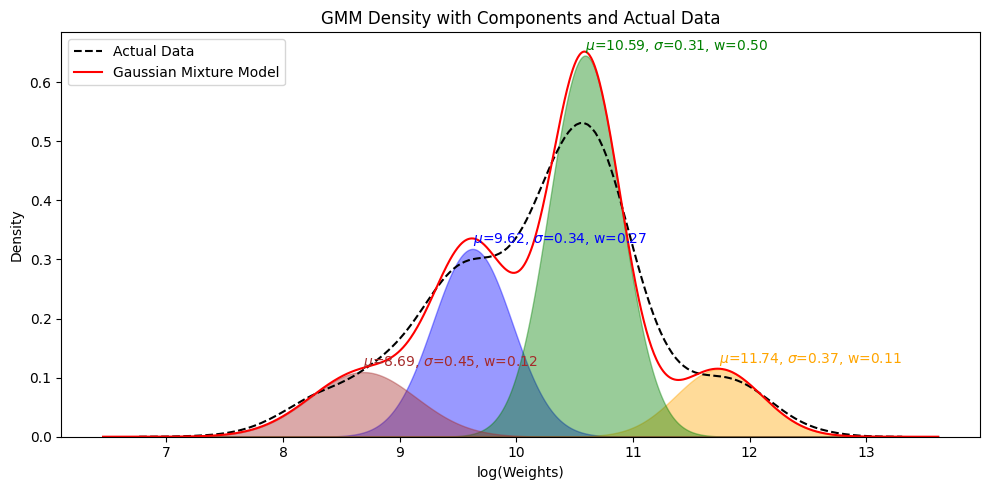

In [52]:
# სიმულირებული მონაცემები
np.random.seed(42)
data = np.concatenate([
    np.random.normal(10.6, 0.35, size=500),
    np.random.normal(9.6, 0.36, size=250),
    np.random.normal(11.8, 0.31, size=80),
    np.random.normal(8.6, 0.52, size=110),
])

# Gaussian Mixture Model (GMM)
gmm = GaussianMixture(n_components=4, random_state=0)
gmm.fit(data.reshape(-1, 1))

# Generate values to evaluate the GMM
x = np.linspace(min(data)-1, max(data)+1, 1000)
logprob = gmm.score_samples(x.reshape(-1, 1))
pdf = np.exp(logprob)  # total GMM density

# Get GMM parameters
weights = gmm.weights_
means = gmm.means_.flatten()
stds = np.sqrt(gmm.covariances_.flatten())

plt.figure(figsize=(10, 5))
sns.kdeplot(data, bw_adjust=1.0, label="Actual Data", color="black", linestyle="--")
plt.plot(x, pdf, label="Gaussian Mixture Model", color="red")

# Plot individual components
colors = ["blue", "orange", "green", "brown"]
for i in range(4):
    component = weights[i] * norm.pdf(x, means[i], stds[i])
    plt.fill_between(x, component, alpha=0.4, color=colors[i])
    plt.text(
        means[i], max(component) + 0.01,
        f"$\\mu$={means[i]:.2f}, $\\sigma$={stds[i]:.2f}, w={weights[i]:.2f}",
        fontsize=10, color=colors[i]
    )

plt.xlabel("log(Weights)")
plt.ylabel("Density")
plt.title("GMM Density with Components and Actual Data")
plt.legend()
plt.tight_layout()
plt.show()

### Synthetic Datasets

In [53]:
X, y = make_blobs(n_samples=1000, centers=3, cluster_std=0.60, random_state=0)

In [54]:
gmm = GaussianMixture(n_components=3, covariance_type="full", random_state=0)
gmm.fit(X)
labels = gmm.predict(X)

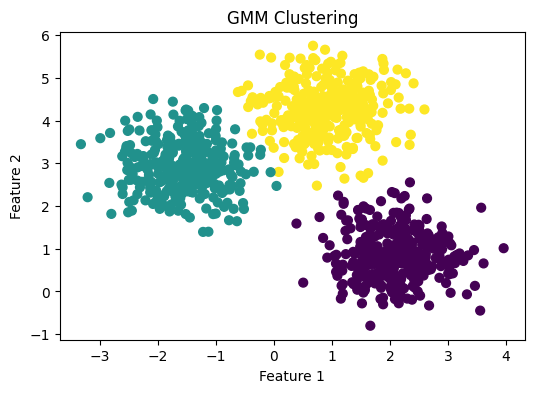

In [55]:
plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], c=labels, s=40, cmap="viridis")
plt.title("GMM Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

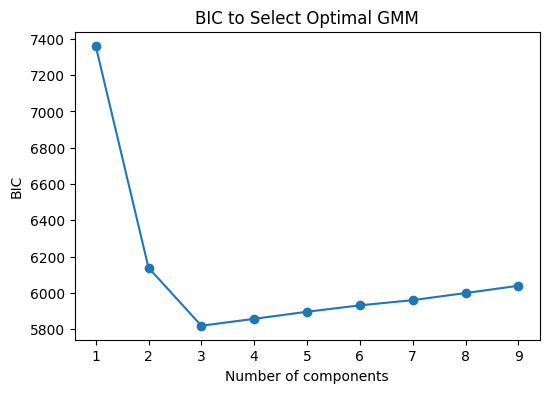

In [56]:
# როგორ შევარჩიოთ კომპონენტების რაოდენობა
bic_scores = []
n_components = range(1, 10)
for n in n_components:
    gmm = GaussianMixture(n_components=n).fit(X)
    bic_scores.append(gmm.bic(X))

plt.figure(figsize=(6, 4))
plt.plot(n_components, bic_scores, marker="o")
plt.xlabel("Number of components")
plt.ylabel("BIC")
plt.title("BIC to Select Optimal GMM")
plt.show()

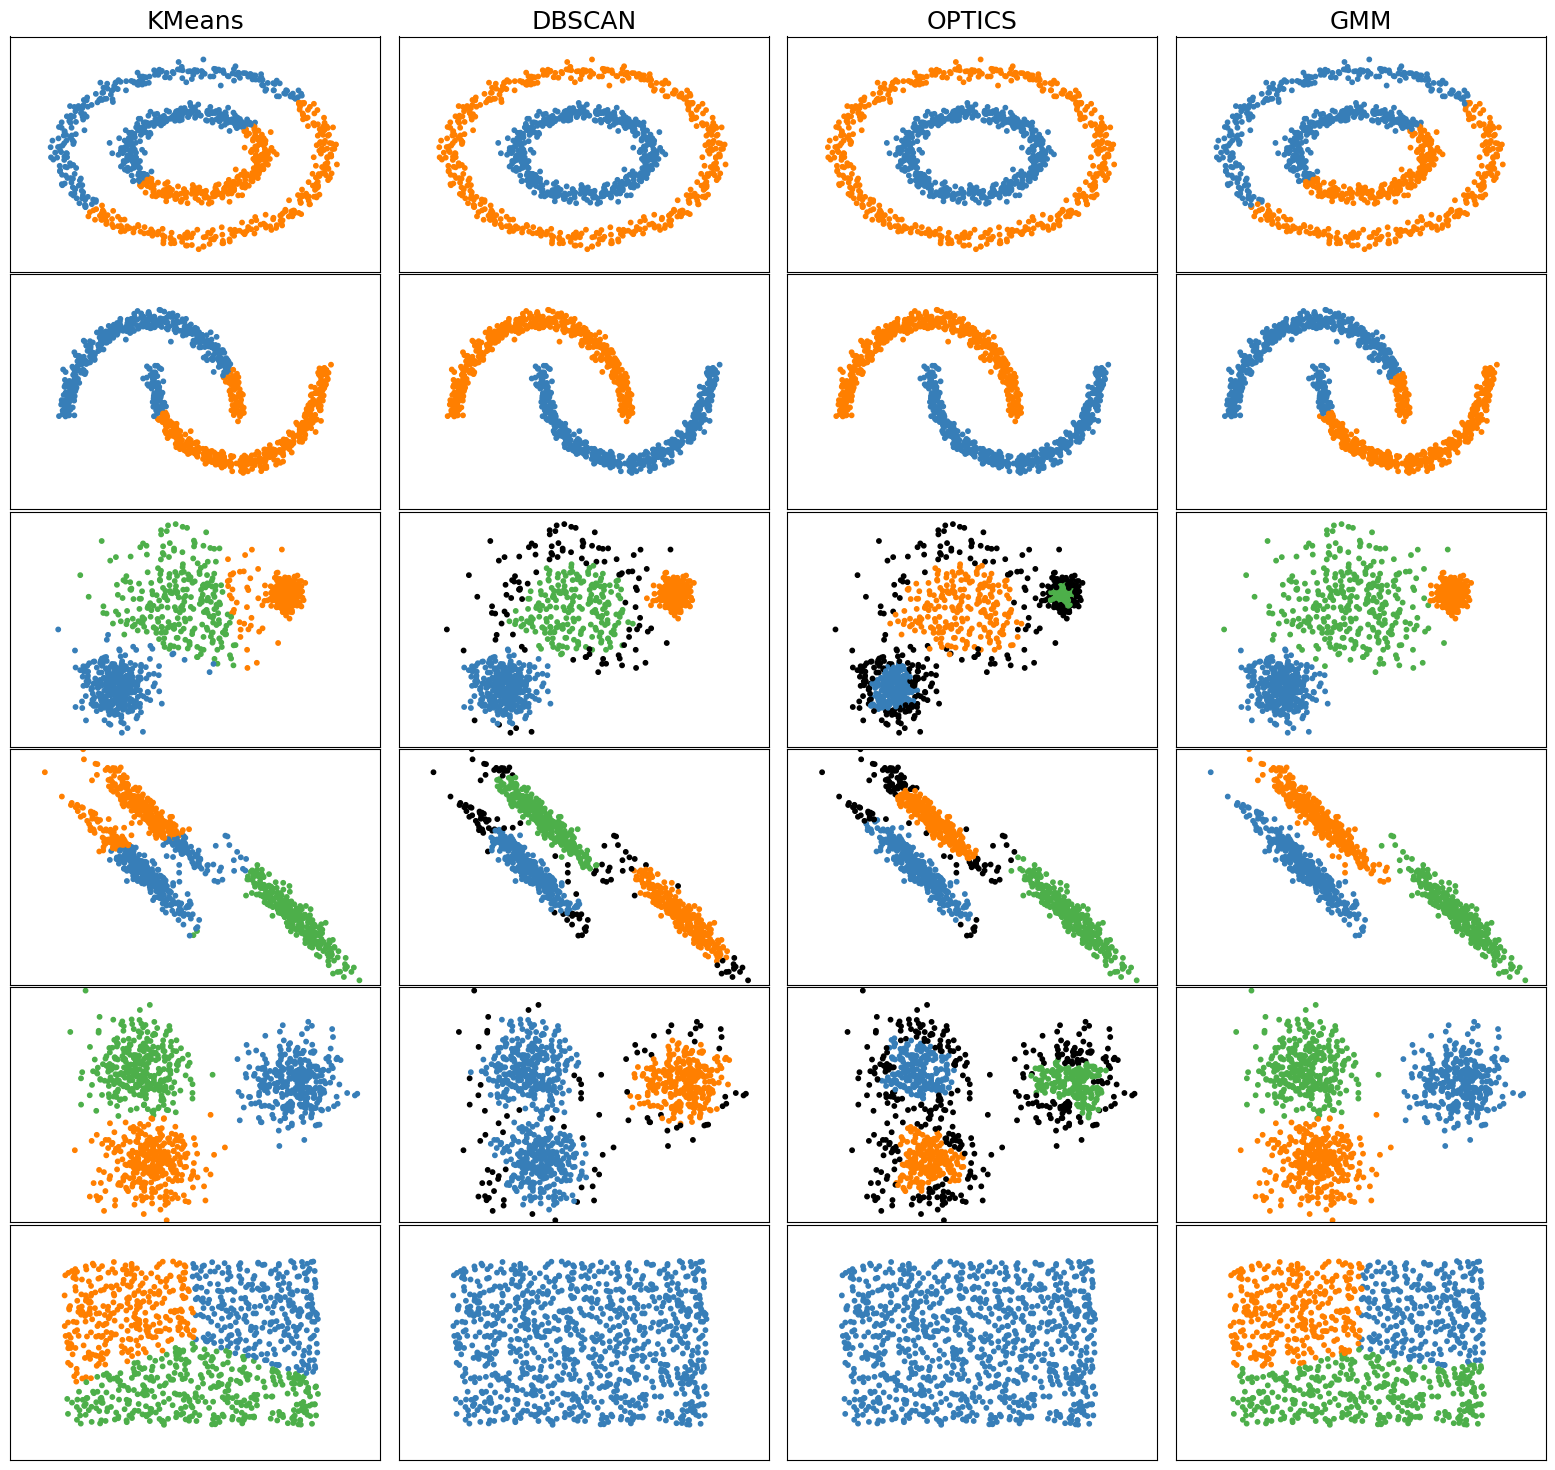

In [130]:
n_samples = 1000
seed = 30
noisy_circles = make_circles(n_samples=n_samples, factor=0.5, noise=0.05, random_state=seed)
noisy_moons = make_moons(n_samples=n_samples, noise=0.05, random_state=seed)
blobs = make_blobs(n_samples=n_samples, random_state=seed)
rng = np.random.RandomState(seed)
no_structure = rng.rand(n_samples, 2), None

random_state = 170
X, y = make_blobs(n_samples=n_samples, random_state=random_state)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)
aniso = (X_aniso, y)

varied = make_blobs(n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=random_state)

plt.figure(figsize=(16, 15))
plt.subplots_adjust(left=0.02, right=0.98, bottom=0.001, top=0.95, wspace=0.05, hspace=0.01)

plot_num = 1

default_base = {
    "quantile": 0.3,
    "eps": 0.3,
    "n_clusters": 3,
    "min_samples": 7,
    "xi": 0.05,
    "min_cluster_size": 0.1,
    "random_state": 42,
}

datasets = [
    (noisy_circles, {"quantile": 0.2, "n_clusters": 2, "xi": 0.08}),
    (noisy_moons, {"n_clusters": 2, "xi": 0.1}),
    (varied, {"eps": 0.2, "min_samples": 10, "xi": 0.01, "min_cluster_size": 0.2}),
    (aniso, {"eps": 0.15, "min_samples": 15, "xi": 0.01, "min_cluster_size": 0.2}),
    (blobs, {"xi": 0.1, "min_cluster_size": 0.2, "eps": 0.15, "min_samples": 5, "xi": 0.01}),
    (no_structure, {}),
]

for i_dataset, (dataset, algo_params) in enumerate(datasets):
    params = default_base.copy()
    params.update(algo_params)

    X, y = dataset
    X = StandardScaler().fit_transform(X)

    kmeans = KMeans(n_clusters=params["n_clusters"], random_state=params["random_state"])
    dbscan = DBSCAN(eps=params["eps"], min_samples=params["min_samples"])
    optics = OPTICS(min_samples=params["min_samples"], xi=params["xi"], min_cluster_size=params["min_cluster_size"])
    gmm = GaussianMixture(n_components=params["n_clusters"], covariance_type="full", random_state=params["random_state"])

    clustering_algorithms = (
        ("KMeans", kmeans),
        ("DBSCAN", dbscan),
        ("OPTICS", optics),
        ("GMM", gmm),
    )

    for name, algorithm in clustering_algorithms:
        algorithm.fit(X)
        y_pred = algorithm.labels_.astype(int) if hasattr(algorithm, "labels_") else algorithm.predict(X)

        plt.subplot(len(datasets), len(clustering_algorithms), plot_num)
        if i_dataset == 0:
            plt.title(name, size=18)

        colors = np.array(list(islice(cycle([
            "#377eb8", "#ff7f00", "#4daf4a", "#f781bf",
            "#a65628", "#984ea3", "#999999", "#e41a1c", "#dede00"
        ]), int(max(y_pred) + 1))))
        colors = np.append(colors, ["#000000"])
        plt.scatter(X[:, 0], X[:, 1], s=10, color=colors[y_pred])
        plt.xlim(-2.5, 2.5)
        plt.ylim(-2.5, 2.5)
        plt.xticks(())
        plt.yticks(())
        plot_num += 1

plt.show()

| **კრიტერიუმი**                               | **K-Means**                                  | **DBSCAN**                        | **OPTICS**                              | **GMM**                  |
| -------------------------------------------- | -------------------------------------------- | --------------------------------- | --------------------------------------- | ----------------------------------------------- |
| კლასტერების რაოდენობა წინასწარ               | ✓                                            | –                                 | –                                       | ✓                                               |
| კლასტერის ფორმა                              | მრგვალი, თანაბარი                            | ნებისმიერი                        | ნებისმიერი                              | ელიფსური                   |
| გადახრისადმი გამძლეობა                       | –                                            | ✓                                 | ✓                                       | –                                               |
| სიხშირის/სიმჭიდროვის გათვალისწინება          | –                                            | ✓                                 | ✓                                       | –                                               |
| იერარქიული სტრუქტურა                         | –                                            | –                                 | ✓ (Ordering-ით)                         | –                                               |
| პარამეტრებზე მგრძნობელობა                    | მაღალი (`k`)                                 | მაღალი (`ε`, `minPts`)            | მაღალი (`minPts`)                  | მაღალი (კომპონენტების რაოდენობა, ინიციალიზაცია) |
| კლასტერის პროგნოზირება შესაძლებელია?         | ✓ (`predict`)                                | –                                 | –                                       | ✓ (`predict_proba`)                             |
| წინასწარი დამუშავება (მაგ. სკალირება)        | ✓ რეკომენდებულია                             | ✓ რეკომენდებულია                  | ✓ რეკომენდებულია                        | ✓ რეკომენდებულია                                |
| ხშირი გამოყენების შემთხვევები                | მომხმარებლის სეგმენტაცია, მარტივი მონაცემები | გეომონაცემები, ხმაური, ანომალიები | რთული სტრუქტურები, ცვალებადი სიმჭიდროვე | შერეული კლასტერების მონაცემები               |
